# 12 — Spatial Zoom + Land/Water Analysis (Kalimantan)

**Purpose:** answer the spatial questions raised during supervision before building a GAT.

This notebook investigates:

1. **Where in Kalimantan is the fire activity concentrated?**
2. **Where do Emerging next-day detections occur?**
3. **Which 0.75° grid cells are predominantly land, mixed land/water, or predominantly water?**
4. **Should any grid cells be excluded from a later graph model?**
5. **What geographic extent is useful for a closer visual zoom?**

---

## Important methodological note

The current analysis unit is a **0.75° grid cell**. A cell is much larger than a river and can also contain both land and water.

Therefore:

> A grid cell must **not** be discarded simply because a river, lake, coastline, or water body is present inside it.

This notebook estimates **land fraction** for each cell and creates a *candidate graph-node mask*. It does **not** permanently remove cells from the modeling dataset.

A cell is only flagged as potentially invalid if it is strongly water-dominant **and** has no observed FIRMS detections during the study period.

---

## Data used

From the existing project:

- `data/intermediate/fire_kalimantan_cell_day_full.csv`
- `model_results/emerging_hotspot/emerging_hotspot_labels_kalimantan.csv`

External geographic context:

- Natural Earth land polygons
- Natural Earth lakes
- Natural Earth rivers / lake centerlines
- Natural Earth administrative level-1 boundaries

Natural Earth is used only for geographic context / masking.  
The wildfire target remains based on the project's FIRMS-derived cell-day data.

In [3]:
# 1. Install/check geospatial dependencies

import sys
import subprocess
import importlib.util

required_packages = {
    "geopandas": "geopandas",
    "shapely": "shapely",
    "pyproj": "pyproj",
    "cartopy": "cartopy",
}

missing = [
    pip_name
    for module_name, pip_name in required_packages.items()
    if importlib.util.find_spec(module_name) is None
]

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *missing]
    )
    print("Installation finished. If imports still fail, restart the kernel once.")
else:
    print("All required geospatial packages are already installed.")

All required geospatial packages are already installed.


In [4]:
# 2. Imports and reproducibility

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from shapely.geometry import box, Point
from shapely.ops import unary_union

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print("GeoPandas:", gpd.__version__)

GeoPandas: 1.1.4


## 3. Resolve project paths

The notebook tries the same local/Colab project locations used in Notebook 11.

In [5]:
# 3. Project paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    fire_candidate = (
        candidate
        / "data"
        / "intermediate"
        / "fire_kalimantan_cell_day_full.csv"
    )

    if fire_candidate.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root could not be detected automatically.\n"
        "Set PROJECT_ROOT manually to the folder containing data/intermediate."
    )

FIRE_PANEL_PATH = (
    PROJECT_ROOT
    / "data"
    / "intermediate"
    / "fire_kalimantan_cell_day_full.csv"
)

EMERGING_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "emerging_hotspot"
    / "emerging_hotspot_labels_kalimantan.csv"
)

RESULTS_DIR = PROJECT_ROOT / "model_results" / "spatial_zoom_landwater"
FIGURES_DIR = RESULTS_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("Fire panel   :", FIRE_PANEL_PATH)
print("Emerging     :", EMERGING_PATH)
print("Results      :", RESULTS_DIR)

if not EMERGING_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 11 output not found: {EMERGING_PATH}\n"
        "Run Notebook 11 through the Save Outputs section first."
    )

PROJECT_ROOT : c:\Users\Asus\Documents\skripsi-karhut
Fire panel   : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\fire_kalimantan_cell_day_full.csv
Emerging     : c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\emerging_hotspot_labels_kalimantan.csv
Results      : c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater


## 4. Load project data

`fire_count` is the number of FIRMS detections assigned to a cell-day.

The Emerging labels come from Notebook 11:

- `Persistent`: next-day positive with recent local activity
- `Emerging`: next-day positive without recent local activity
- `Negative`: no next-day positive detection

In [6]:
# 4. Load data

fire = pd.read_csv(FIRE_PANEL_PATH, parse_dates=["date"])
events = pd.read_csv(
    EMERGING_PATH,
    parse_dates=["date", "target_date"],
)

fire = fire.sort_values(["cell_id", "date"]).reset_index(drop=True)
events = events.sort_values(["cell_id", "date"]).reset_index(drop=True)

print("Fire panel shape :", fire.shape)
print(
    "Fire date range  :",
    fire["date"].min().date(),
    "→",
    fire["date"].max().date(),
)
print("Unique cells     :", fire["cell_id"].nunique())

print()
print("Event-label shape:", events.shape)
print(
    "Event date range :",
    events["date"].min().date(),
    "→",
    events["date"].max().date(),
)

required_fire = {
    "cell_id",
    "grid_lat",
    "grid_lon",
    "date",
    "fire_count",
    "fire_active",
}

required_events = {
    "cell_id",
    "grid_lat",
    "grid_lon",
    "date",
    "event_type_7d",
    "event_type_3d",
    "split",
}

missing_fire = sorted(required_fire - set(fire.columns))
missing_events = sorted(required_events - set(events.columns))

if missing_fire:
    raise ValueError(f"Missing fire-panel columns: {missing_fire}")

if missing_events:
    raise ValueError(f"Missing Notebook 11 columns: {missing_events}")

assert fire["cell_id"].nunique() == 272, (
    "Expected 272 Kalimantan cells from the existing pipeline."
)

print("\nSchema checks passed.")

Fire panel shape : (36448, 11)
Fire date range  : 2026-05-01 → 2026-09-11
Unique cells     : 272

Event-label shape: (34272, 14)
Event date range : 2026-05-08 → 2026-09-10

Schema checks passed.


## 5. Reconstruct the 0.75° grid geometry

Notebook 03 used the AQ grid coordinates as cell centers.  
The latitude and longitude spacing is inferred from the actual data rather than hard-coded.

A rectangular cell polygon is created around each grid center using half of the inferred spacing.

In [7]:
# 5. Infer grid spacing and create polygons

cell_table = (
    fire[
        ["cell_id", "grid_lat", "grid_lon"]
    ]
    .drop_duplicates()
    .sort_values(["grid_lat", "grid_lon"])
    .reset_index(drop=True)
)

lat_values = np.sort(cell_table["grid_lat"].unique())
lon_values = np.sort(cell_table["grid_lon"].unique())

lat_step = float(np.median(np.diff(lat_values)))
lon_step = float(np.median(np.diff(lon_values)))

print("Unique latitudes :", len(lat_values))
print("Unique longitudes:", len(lon_values))
print("Latitude spacing :", lat_step)
print("Longitude spacing:", lon_step)

if not np.isclose(lat_step, 0.75):
    print("WARNING: inferred latitude spacing is not 0.75°.")

if not np.isclose(lon_step, 0.75):
    print("WARNING: inferred longitude spacing is not 0.75°.")

half_lat = lat_step / 2
half_lon = lon_step / 2

cell_table["geometry"] = [
    box(
        lon - half_lon,
        lat - half_lat,
        lon + half_lon,
        lat + half_lat,
    )
    for lat, lon in zip(
        cell_table["grid_lat"],
        cell_table["grid_lon"],
    )
]

grid_gdf = gpd.GeoDataFrame(
    cell_table,
    geometry="geometry",
    crs="EPSG:4326",
)

print("Grid polygons:", len(grid_gdf))
display(grid_gdf.head())

Unique latitudes : 17
Unique longitudes: 16
Latitude spacing : 0.75
Longitude spacing: 0.75
Grid polygons: 272


,cell_id,grid_lat,grid_lon,geometry
0,Kalimantan_-4.50_108.00,-4.5,108.00,"POLYGON ((108.375 -4.875, 108.375 -4.125, 107...."
1,Kalimantan_-4.50_108.75,-4.5,108.75,"POLYGON ((109.125 -4.875, 109.125 -4.125, 108...."
2,Kalimantan_-4.50_109.50,-4.5,109.50,"POLYGON ((109.875 -4.875, 109.875 -4.125, 109...."
3,Kalimantan_-4.50_110.25,-4.5,110.25,"POLYGON ((110.625 -4.875, 110.625 -4.125, 109...."
4,Kalimantan_-4.50_111.00,-4.5,111.00,"POLYGON ((111.375 -4.875, 111.375 -4.125, 110...."


## 6. Aggregate total fire activity and Emerging detections by cell

Several cell-level quantities are created:

- total FIRMS detection count
- number of active cell-days
- total FRP
- number of 7-day Emerging positives
- number of 3-day Emerging positives
- validation-only Emerging counts

These are descriptive spatial diagnostics, not model features yet.

In [8]:
# 6. Aggregate activity by cell

fire_cell_summary = (
    fire
    .groupby(
        ["cell_id", "grid_lat", "grid_lon"],
        as_index=False,
    )
    .agg(
        total_fire_count=("fire_count", "sum"),
        active_cell_days=("fire_active", "sum"),
        total_frp=("frp_sum", "sum"),
    )
)

event_cell_summary = (
    events
    .groupby(
        ["cell_id", "grid_lat", "grid_lon"],
        as_index=False,
    )
    .agg(
        emerging_7d_all=(
            "event_type_7d",
            lambda s: (s == "Emerging").sum(),
        ),
        emerging_3d_all=(
            "event_type_3d",
            lambda s: (s == "Emerging").sum(),
        ),
        persistent_7d_all=(
            "event_type_7d",
            lambda s: (s == "Persistent").sum(),
        ),
    )
)

val_events = events[events["split"].eq("Validation")].copy()

val_cell_summary = (
    val_events
    .groupby(
        ["cell_id", "grid_lat", "grid_lon"],
        as_index=False,
    )
    .agg(
        validation_emerging_7d=(
            "event_type_7d",
            lambda s: (s == "Emerging").sum(),
        ),
        validation_emerging_3d=(
            "event_type_3d",
            lambda s: (s == "Emerging").sum(),
        ),
    )
)

cell_summary = (
    grid_gdf
    .merge(
        fire_cell_summary,
        on=["cell_id", "grid_lat", "grid_lon"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        event_cell_summary,
        on=["cell_id", "grid_lat", "grid_lon"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        val_cell_summary,
        on=["cell_id", "grid_lat", "grid_lon"],
        how="left",
        validate="one_to_one",
    )
)

numeric_fill = [
    "total_fire_count",
    "active_cell_days",
    "total_frp",
    "emerging_7d_all",
    "emerging_3d_all",
    "persistent_7d_all",
    "validation_emerging_7d",
    "validation_emerging_3d",
]

cell_summary[numeric_fill] = (
    cell_summary[numeric_fill]
    .fillna(0)
)

cell_summary = gpd.GeoDataFrame(
    cell_summary,
    geometry="geometry",
    crs="EPSG:4326",
)

display(
    cell_summary
    .sort_values(
        "total_fire_count",
        ascending=False,
    )
    .head(15)[
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "total_fire_count",
            "active_cell_days",
            "emerging_7d_all",
            "validation_emerging_7d",
        ]
    ]
)

,cell_id,grid_lat,grid_lon,total_fire_count,active_cell_days,emerging_7d_all,validation_emerging_7d
56,Kalimantan_-2.25_114.00,-2.25,114.00,13251.0,60.0,1,0
67,Kalimantan_-1.50_110.25,-1.50,110.25,11270.0,78.0,3,0
51,Kalimantan_-2.25_110.25,-2.25,110.25,8133.0,75.0,3,0
83,Kalimantan_-0.75_110.25,-0.75,110.25,5851.0,71.0,3,0
55,Kalimantan_-2.25_113.25,-2.25,113.25,5517.0,59.0,1,0
98,Kalimantan_0.00_109.50,0.00,109.50,5241.0,76.0,3,0
40,Kalimantan_-3.00_114.00,-3.00,114.00,4925.0,56.0,4,0
38,Kalimantan_-3.00_112.50,-3.00,112.50,4897.0,72.0,3,0
41,Kalimantan_-3.00_114.75,-3.00,114.75,4826.0,93.0,0,0
39,Kalimantan_-3.00_113.25,-3.00,113.25,4409.0,48.0,2,0


## 7. Download Natural Earth geographic layers

Cartopy downloads and caches the Natural Earth shapefiles the first time this cell is executed.

We use:

- `land`
- `lakes`
- `rivers_lake_centerlines`
- `admin_0_boundary_lines_land`
- `admin_1_states_provinces`

The 10m scale is used because the purpose is to inspect coastline/lakes relative to the coarse 0.75° modeling grid.

In [9]:
# 7. Natural Earth paths

NE_RESOLUTION = "10m"

land_path = shapereader.natural_earth(
    resolution=NE_RESOLUTION,
    category="physical",
    name="land",
)

lakes_path = shapereader.natural_earth(
    resolution=NE_RESOLUTION,
    category="physical",
    name="lakes",
)

rivers_path = shapereader.natural_earth(
    resolution=NE_RESOLUTION,
    category="physical",
    name="rivers_lake_centerlines",
)

admin0_path = shapereader.natural_earth(
    resolution=NE_RESOLUTION,
    category="cultural",
    name="admin_0_boundary_lines_land",
)

admin1_path = shapereader.natural_earth(
    resolution=NE_RESOLUTION,
    category="cultural",
    name="admin_1_states_provinces",
)

print("Natural Earth layers ready.")

c:\Users\Asus\Documents\skripsi-karhut\.venv\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\Asus\Documents\skripsi-karhut\.venv\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\Asus\Documents\skripsi-karhut\.venv\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_rivers_lake_centerlines.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\Asus\Documents\skripsi-karhut\.venv\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}'

Natural Earth layers ready.


## 8. Build a terrestrial-surface mask

The grid bounding box is expanded slightly, then only nearby Natural Earth land/lake geometries are retained.

For this analysis:

> **terrestrial surface = land polygon − lake polygon**

Rivers are plotted later as line context. They are **not** subtracted from grid area because their widths are tiny relative to a 0.75° cell and the Natural Earth river layer is represented primarily as centerlines.

In [10]:
# 8. Build local land/lake geometry

minx, miny, maxx, maxy = cell_summary.total_bounds

analysis_bbox = box(
    minx - 1.0,
    miny - 1.0,
    maxx + 1.0,
    maxy + 1.0,
)

def local_geometries(path, bbox):
    reader = shapereader.Reader(path)
    geoms = []

    for geom in reader.geometries():
        if geom.intersects(bbox):
            clipped = geom.intersection(bbox)
            if not clipped.is_empty:
                geoms.append(clipped)

    return geoms

local_land = local_geometries(
    land_path,
    analysis_bbox,
)

local_lakes = local_geometries(
    lakes_path,
    analysis_bbox,
)

print("Local land pieces :", len(local_land))
print("Local lake pieces :", len(local_lakes))

land_union = unary_union(local_land)

if local_lakes:
    lakes_union = unary_union(local_lakes)
    terrestrial_union = land_union.difference(lakes_union)
else:
    lakes_union = None
    terrestrial_union = land_union

terrestrial_gdf = gpd.GeoDataFrame(
    {"layer": ["terrestrial"]},
    geometry=[terrestrial_union],
    crs="EPSG:4326",
)

print("Terrestrial geometry constructed.")

Local land pieces : 9
Local lake pieces : 2
Terrestrial geometry constructed.


## 9. Estimate land fraction for every grid cell

Area calculations are performed after projection to **EPSG:6933**, a global equal-area CRS.

For each grid cell:

\[
land\_fraction =

rac{	ext{terrestrial area inside cell}}
{	ext{total cell area}}
\]

This is a coarse geographic screening variable; it is not a substitute for a high-resolution land-cover dataset.

In [11]:
# 9. Equal-area land-fraction calculation

AREA_CRS = "EPSG:6933"

grid_equal = cell_summary.to_crs(AREA_CRS)
land_equal = terrestrial_gdf.to_crs(AREA_CRS).geometry.iloc[0]

grid_equal["cell_area_km2"] = (
    grid_equal.geometry.area / 1_000_000
)

grid_equal["land_area_km2"] = (
    grid_equal.geometry
    .intersection(land_equal)
    .area
    / 1_000_000
)

grid_equal["land_fraction"] = (
    grid_equal["land_area_km2"]
    / grid_equal["cell_area_km2"]
).clip(0, 1)

cell_summary["cell_area_km2"] = (
    grid_equal["cell_area_km2"].to_numpy()
)

cell_summary["land_area_km2"] = (
    grid_equal["land_area_km2"].to_numpy()
)

cell_summary["land_fraction"] = (
    grid_equal["land_fraction"].to_numpy()
)

display(
    cell_summary[
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "land_fraction",
            "total_fire_count",
        ]
    ]
    .sort_values("land_fraction")
    .head(20)
)

,cell_id,grid_lat,grid_lon,land_fraction,total_fire_count
16,Kalimantan_-3.75_108.00,-3.75,108.00,0.0,0.0
17,Kalimantan_-3.75_108.75,-3.75,108.75,0.0,0.0
18,Kalimantan_-3.75_109.50,-3.75,109.50,0.0,0.0
19,Kalimantan_-3.75_110.25,-3.75,110.25,0.0,0.0
20,Kalimantan_-3.75_111.00,-3.75,111.00,0.0,0.0
29,Kalimantan_-3.75_117.75,-3.75,117.75,0.0,0.0
28,Kalimantan_-3.75_117.00,-3.75,117.00,0.0,0.0
244,Kalimantan_6.75_111.00,6.75,111.00,0.0,0.0
44,Kalimantan_-3.00_117.00,-3.00,117.00,0.0,0.0
45,Kalimantan_-3.00_117.75,-3.00,117.75,0.0,0.0


## 10. Create interpretable land/water classes

These thresholds are **diagnostic only**:

- **Land-dominant:** land fraction ≥ 0.80
- **Mixed:** 0.20 ≤ land fraction < 0.80
- **Water-dominant:** land fraction < 0.20

A later graph should **not automatically remove all mixed cells**.

The most conservative candidate exclusion rule is:

> water-dominant **and** no observed FIRMS detections during the full study period.

In [12]:
# 10. Land/water classes and conservative node mask

cell_summary["surface_class"] = pd.cut(
    cell_summary["land_fraction"],
    bins=[-0.001, 0.20, 0.80, 1.001],
    labels=[
        "Water-dominant",
        "Mixed land/water",
        "Land-dominant",
    ],
    right=False,
)

cell_summary["has_any_fire_detection"] = (
    cell_summary["total_fire_count"] > 0
)

cell_summary["candidate_exclude_from_graph"] = (
    (cell_summary["land_fraction"] < 0.20)
    &
    (~cell_summary["has_any_fire_detection"])
)

surface_summary = (
    cell_summary
    .groupby(
        "surface_class",
        observed=False,
    )
    .agg(
        cells=("cell_id", "size"),
        cells_with_fire=("has_any_fire_detection", "sum"),
        total_fire_count=("total_fire_count", "sum"),
        emerging_7d_all=("emerging_7d_all", "sum"),
        validation_emerging_7d=(
            "validation_emerging_7d",
            "sum",
        ),
    )
)

display(surface_summary)

print(
    "Candidate graph exclusions:",
    int(cell_summary["candidate_exclude_from_graph"].sum()),
)

display(
    cell_summary[
        cell_summary["candidate_exclude_from_graph"]
    ][
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "land_fraction",
            "total_fire_count",
        ]
    ]
    .sort_values("land_fraction")
)

,cells,cells_with_fire,total_fire_count,emerging_7d_all,validation_emerging_7d
surface_class,,,,,
Water-dominant,145,39,2868.0,108,34
Mixed land/water,34,34,30284.0,124,18
Land-dominant,93,93,113162.0,271,40


Candidate graph exclusions: 106


,cell_id,grid_lat,grid_lon,land_fraction,total_fire_count
0,Kalimantan_-4.50_108.00,-4.50,108.00,0.000000,0.0
1,Kalimantan_-4.50_108.75,-4.50,108.75,0.000000,0.0
2,Kalimantan_-4.50_109.50,-4.50,109.50,0.000000,0.0
3,Kalimantan_-4.50_110.25,-4.50,110.25,0.000000,0.0
4,Kalimantan_-4.50_111.00,-4.50,111.00,0.000000,0.0
...,...,...,...,...,...
254,Kalimantan_6.75_118.50,6.75,118.50,0.011123,0.0
207,Kalimantan_4.50_119.25,4.50,119.25,0.014661,0.0
164,Kalimantan_3.00_111.00,3.00,111.00,0.018439,0.0
15,Kalimantan_-4.50_119.25,-4.50,119.25,0.064763,0.0


## 11. Load approximate administrative boundaries

Natural Earth admin-1 boundaries are used only to give geographic context such as **West / Central / South / East / North Kalimantan** where available.

Because the modeling grid is coarse, province assignment should be interpreted as approximate.

We assign a province label based on the **grid-cell center point**, not the entire cell polygon.

In [13]:
# 11. Natural Earth admin-1 context

admin1_records = list(
    shapereader.Reader(admin1_path).records()
)

grid_center_bbox = box(
    minx - 0.5,
    miny - 0.5,
    maxx + 0.5,
    maxy + 0.5,
)

admin_rows = []

for rec in admin1_records:
    attrs = rec.attributes
    geom = rec.geometry

    if not geom.intersects(grid_center_bbox):
        continue

    country_candidates = [
        attrs.get("adm0_a3"),
        attrs.get("adm0_a3_us"),
        attrs.get("admin"),
        attrs.get("geonunit"),
    ]

    if (
        "IDN" in country_candidates
        or "Indonesia" in country_candidates
    ):
        admin_rows.append({
            "province": (
                attrs.get("name")
                or attrs.get("name_en")
                or attrs.get("region")
                or "Unknown"
            ),
            "geometry": geom,
        })

admin1_gdf = gpd.GeoDataFrame(
    admin_rows,
    geometry="geometry",
    crs="EPSG:4326",
)

print("Indonesia admin-1 features in/near grid:", len(admin1_gdf))

if len(admin1_gdf):
    display(admin1_gdf[["province"]])
else:
    print(
        "No admin-1 polygons were matched automatically. "
        "Maps will still work without province labels."
    )

Indonesia admin-1 features in/near grid: 9


,province
0,Kalimantan Timur
1,Kalimantan Barat
2,Sulawesi Selatan
3,Sulawesi Tengah
4,Kepulauan Riau
5,Sulawesi Barat
6,Kalimantan Tengah
7,Kalimantan Selatan
8,Bangka-Belitung


In [14]:
# 11b. Assign approximate province by grid-center point

centers = cell_summary[
    [
        "cell_id",
        "grid_lat",
        "grid_lon",
    ]
].copy()

centers["geometry"] = [
    Point(lon, lat)
    for lat, lon in zip(
        centers["grid_lat"],
        centers["grid_lon"],
    )
]

centers_gdf = gpd.GeoDataFrame(
    centers,
    geometry="geometry",
    crs="EPSG:4326",
)

if len(admin1_gdf):
    center_with_admin = gpd.sjoin(
        centers_gdf,
        admin1_gdf[
            ["province", "geometry"]
        ],
        how="left",
        predicate="within",
    )

    center_with_admin = (
        center_with_admin[
            ["cell_id", "province"]
        ]
        .drop_duplicates("cell_id")
    )

    cell_summary = cell_summary.merge(
        center_with_admin,
        on="cell_id",
        how="left",
        validate="one_to_one",
    )
else:
    cell_summary["province"] = np.nan

display(
    cell_summary[
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "province",
            "total_fire_count",
            "emerging_7d_all",
        ]
    ]
    .sort_values(
        "total_fire_count",
        ascending=False,
    )
    .head(20)
)

,cell_id,grid_lat,grid_lon,province,total_fire_count,emerging_7d_all
56,Kalimantan_-2.25_114.00,-2.25,114.00,Kalimantan Tengah,13251.0,1
67,Kalimantan_-1.50_110.25,-1.50,110.25,Kalimantan Barat,11270.0,3
51,Kalimantan_-2.25_110.25,-2.25,110.25,Kalimantan Barat,8133.0,3
83,Kalimantan_-0.75_110.25,-0.75,110.25,Kalimantan Barat,5851.0,3
55,Kalimantan_-2.25_113.25,-2.25,113.25,Kalimantan Tengah,5517.0,1
98,Kalimantan_0.00_109.50,0.00,109.50,Kalimantan Barat,5241.0,3
40,Kalimantan_-3.00_114.00,-3.00,114.00,Kalimantan Tengah,4925.0,4
38,Kalimantan_-3.00_112.50,-3.00,112.50,Kalimantan Tengah,4897.0,3
41,Kalimantan_-3.00_114.75,-3.00,114.75,Kalimantan Selatan,4826.0,0
39,Kalimantan_-3.00_113.25,-3.00,113.25,Kalimantan Tengah,4409.0,2


## 12. Approximate activity by province

This table is for **orientation**, not exact administrative statistics.

Why approximate?

- the cells are 0.75° wide;
- some cells cross provincial borders;
- fire detections were assigned to the nearest grid center;
- province is assigned from the cell center.

The main unit of analysis remains the grid cell.

In [15]:
# 12. Approximate province-level activity context

province_summary = (
    cell_summary
    .dropna(subset=["province"])
    .groupby(
        "province",
        as_index=False,
    )
    .agg(
        grid_cells=("cell_id", "size"),
        total_fire_count=("total_fire_count", "sum"),
        active_cell_days=("active_cell_days", "sum"),
        emerging_7d_all=("emerging_7d_all", "sum"),
        emerging_3d_all=("emerging_3d_all", "sum"),
        validation_emerging_7d=(
            "validation_emerging_7d",
            "sum",
        ),
    )
    .sort_values(
        "total_fire_count",
        ascending=False,
    )
)

display(province_summary)

,province,grid_cells,total_fire_count,active_cell_days,emerging_7d_all,emerging_3d_all,validation_emerging_7d
1,Kalimantan Barat,22,55344.0,1335.0,60,137,2
3,Kalimantan Tengah,20,53484.0,1079.0,57,105,4
4,Kalimantan Timur,28,14911.0,1336.0,79,178,7
2,Kalimantan Selatan,8,12888.0,602.0,18,39,0
5,Sulawesi Barat,2,409.0,100.0,8,14,2
0,Bangka-Belitung,1,269.0,58.0,3,4,0


## 13. Identify high-activity grid cells

Two ranked tables are useful for supervision:

1. cells with the highest total FIRMS detection counts;
2. cells with the highest Emerging counts.

This gives a concrete answer to:

> "Kalimantannya spesifik di mana?"

In [16]:
# 13. Top cells

top_fire_cells = (
    cell_summary
    .sort_values(
        "total_fire_count",
        ascending=False,
    )
    [
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "province",
            "land_fraction",
            "total_fire_count",
            "active_cell_days",
        ]
    ]
    .head(20)
)

top_emerging_cells = (
    cell_summary
    .sort_values(
        [
            "emerging_7d_all",
            "total_fire_count",
        ],
        ascending=False,
    )
    [
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "province",
            "land_fraction",
            "emerging_7d_all",
            "emerging_3d_all",
            "validation_emerging_7d",
            "total_fire_count",
        ]
    ]
    .head(20)
)

print("=== Top cells by total FIRMS detections ===")
display(top_fire_cells)

print("\n=== Top cells by 7-day Emerging detections ===")
display(top_emerging_cells)

=== Top cells by total FIRMS detections ===


,cell_id,grid_lat,grid_lon,province,land_fraction,total_fire_count,active_cell_days
56,Kalimantan_-2.25_114.00,-2.25,114.00,Kalimantan Tengah,1.000000,13251.0,60.0
67,Kalimantan_-1.50_110.25,-1.50,110.25,Kalimantan Barat,0.831393,11270.0,78.0
51,Kalimantan_-2.25_110.25,-2.25,110.25,Kalimantan Barat,0.655494,8133.0,75.0
83,Kalimantan_-0.75_110.25,-0.75,110.25,Kalimantan Barat,0.997368,5851.0,71.0
55,Kalimantan_-2.25_113.25,-2.25,113.25,Kalimantan Tengah,1.000000,5517.0,59.0
98,Kalimantan_0.00_109.50,0.00,109.50,Kalimantan Barat,0.956682,5241.0,76.0
40,Kalimantan_-3.00_114.00,-3.00,114.00,Kalimantan Tengah,0.976820,4925.0,56.0
38,Kalimantan_-3.00_112.50,-3.00,112.50,Kalimantan Tengah,0.958826,4897.0,72.0
41,Kalimantan_-3.00_114.75,-3.00,114.75,Kalimantan Selatan,0.998869,4826.0,93.0
39,Kalimantan_-3.00_113.25,-3.00,113.25,Kalimantan Tengah,0.702839,4409.0,48.0



=== Top cells by 7-day Emerging detections ===


,cell_id,grid_lat,grid_lon,province,land_fraction,emerging_7d_all,emerging_3d_all,validation_emerging_7d,total_fire_count
220,Kalimantan_5.25_117.00,5.25,117.00,NaN,1.000000,7,10,1,41.0
232,Kalimantan_6.00_114.00,6.00,114.00,NaN,0.000000,7,7,1,25.0
148,Kalimantan_2.25_111.00,2.25,111.00,NaN,0.181946,7,9,2,23.0
46,Kalimantan_-3.00_118.50,-3.00,118.50,NaN,0.074173,7,8,2,21.0
53,Kalimantan_-2.25_111.75,-2.25,111.75,Kalimantan Tengah,1.000000,6,8,0,902.0
107,Kalimantan_0.00_116.25,0.00,116.25,Kalimantan Timur,0.968896,6,8,0,440.0
172,Kalimantan_3.00_117.00,3.00,117.00,Kalimantan Timur,0.989981,6,8,0,369.0
187,Kalimantan_3.75_116.25,3.75,116.25,Kalimantan Timur,1.000000,6,9,0,168.0
31,Kalimantan_-3.75_119.25,-3.75,119.25,NaN,0.253957,6,9,1,65.0
189,Kalimantan_3.75_117.75,3.75,117.75,NaN,0.350105,6,12,2,57.0


## 14. Calculate fire-activity concentration and a data-driven zoom extent

Rather than manually choosing a province, we calculate the smallest **cell set** that accounts for approximately 80% of all FIRMS detections.

The bounding box of those cells is used only as a **visual zoom recommendation**.

It does **not** automatically redefine the thesis study area.

In [17]:
# 14. Cells covering ~80% of all fire detections

activity_ranked = (
    cell_summary
    .sort_values(
        "total_fire_count",
        ascending=False,
    )
    .copy()
)

total_detections = activity_ranked["total_fire_count"].sum()

if total_detections <= 0:
    raise ValueError("No fire detections found.")

activity_ranked["activity_share"] = (
    activity_ranked["total_fire_count"]
    / total_detections
)

activity_ranked["cumulative_activity_share"] = (
    activity_ranked["activity_share"].cumsum()
)

# Include all rows before 80%, plus the first row crossing 80%.
crossing_idx = np.argmax(
    activity_ranked["cumulative_activity_share"].to_numpy()
    >= 0.80
)

activity_core = activity_ranked.iloc[
    : crossing_idx + 1
].copy()

core_share = (
    activity_core["total_fire_count"].sum()
    / total_detections
)

core_minx, core_miny, core_maxx, core_maxy = (
    activity_core.total_bounds
)

zoom_margin = max(lat_step, lon_step)

FIRE_ZOOM_EXTENT = [
    core_minx - zoom_margin,
    core_maxx + zoom_margin,
    core_miny - zoom_margin,
    core_maxy + zoom_margin,
]

print("Cells in 80% activity core:", len(activity_core))
print("Actual share covered       :", round(core_share, 4))
print("Recommended visual extent  :", FIRE_ZOOM_EXTENT)

display(
    activity_core[
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "province",
            "total_fire_count",
            "cumulative_activity_share",
        ]
    ].head(30)
)

Cells in 80% activity core: 31
Actual share covered       : 0.8028
Recommended visual extent  : [np.float64(108.375), np.float64(118.875), np.float64(-4.875), np.float64(3.375)]


,cell_id,grid_lat,grid_lon,province,total_fire_count,cumulative_activity_share
56,Kalimantan_-2.25_114.00,-2.25,114.00,Kalimantan Tengah,13251.0,0.090565
67,Kalimantan_-1.50_110.25,-1.50,110.25,Kalimantan Barat,11270.0,0.167592
51,Kalimantan_-2.25_110.25,-2.25,110.25,Kalimantan Barat,8133.0,0.223178
83,Kalimantan_-0.75_110.25,-0.75,110.25,Kalimantan Barat,5851.0,0.263167
55,Kalimantan_-2.25_113.25,-2.25,113.25,Kalimantan Tengah,5517.0,0.300873
98,Kalimantan_0.00_109.50,0.00,109.50,Kalimantan Barat,5241.0,0.336694
40,Kalimantan_-3.00_114.00,-3.00,114.00,Kalimantan Tengah,4925.0,0.370354
38,Kalimantan_-3.00_112.50,-3.00,112.50,Kalimantan Tengah,4897.0,0.403823
41,Kalimantan_-3.00_114.75,-3.00,114.75,Kalimantan Selatan,4826.0,0.436807
39,Kalimantan_-3.00_113.25,-3.00,113.25,Kalimantan Tengah,4409.0,0.466941


## 15. Activity-weighted geographic center

This is another compact descriptive answer for supervision.

It is the weighted mean grid coordinate using total detection count as weight.

It is **not** claimed to be a fire "center" in a physical or causal sense.

In [18]:
# 15. Weighted activity center

weights = cell_summary["total_fire_count"].to_numpy(dtype=float)

weighted_lat = np.average(
    cell_summary["grid_lat"],
    weights=weights,
)

weighted_lon = np.average(
    cell_summary["grid_lon"],
    weights=weights,
)

print(
    "Activity-weighted grid coordinate:",
    f"lat={weighted_lat:.3f}, lon={weighted_lon:.3f}",
)

Activity-weighted grid coordinate: lat=-1.311, lon=112.768


# MAPS

The next figures are intentionally separate rather than combined into subplots.

The maps show the same 0.75° grid used by the modeling pipeline.

In [19]:
# 16. Helper functions for geographic maps

MAP_EXTENT = [
    minx - 0.5,
    maxx + 0.5,
    miny - 0.5,
    maxy + 0.5,
]

def add_base_map(ax, extent=MAP_EXTENT, show_rivers=True):
    ax.set_extent(
        extent,
        crs=ccrs.PlateCarree(),
    )

    ax.add_feature(
        cfeature.LAND,
        alpha=0.12,
    )

    ax.add_feature(
        cfeature.OCEAN,
        alpha=0.08,
    )

    ax.add_feature(
        cfeature.COASTLINE.with_scale("10m"),
        linewidth=0.8,
    )

    ax.add_feature(
        cfeature.BORDERS.with_scale("10m"),
        linewidth=0.7,
    )

    ax.add_feature(
        cfeature.LAKES.with_scale("10m"),
        alpha=0.25,
    )

    if show_rivers:
        ax.add_feature(
            cfeature.RIVERS.with_scale("10m"),
            linewidth=0.5,
            alpha=0.5,
        )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.4,
        alpha=0.4,
    )

    gl.top_labels = False
    gl.right_labels = False

    return ax


def plot_grid_boundaries(ax, gdf):
    for geom in gdf.geometry:
        x, y = geom.exterior.xy
        ax.plot(
            x,
            y,
            linewidth=0.35,
            alpha=0.35,
            transform=ccrs.PlateCarree(),
        )

## 17. Map — Full modeling grid footprint

This map answers the first basic question:

> How broad is the current "Kalimantan" grid actually?

The plotted rectangles represent the 272 modeling cells.

c:\Users\Asus\Documents\skripsi-karhut\.venv\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\Asus\Documents\skripsi-karhut\.venv\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


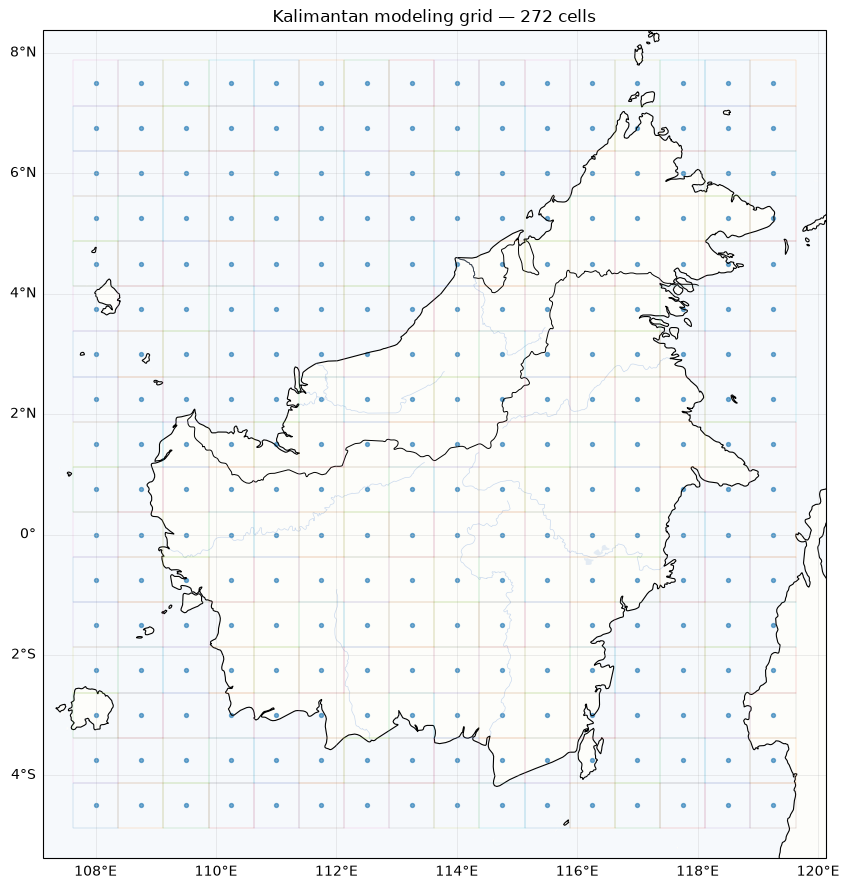

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\figures\01_full_modeling_grid.png


In [20]:
# 17. Full 272-cell modeling grid

fig = plt.figure(figsize=(10, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

add_base_map(ax)
plot_grid_boundaries(ax, cell_summary)

ax.scatter(
    cell_summary["grid_lon"],
    cell_summary["grid_lat"],
    s=8,
    alpha=0.6,
    transform=ccrs.PlateCarree(),
)

ax.set_title("Kalimantan modeling grid — 272 cells")

plt.tight_layout()

fig_path = FIGURES_DIR / "01_full_modeling_grid.png"
plt.savefig(
    fig_path,
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Saved:", fig_path)

## 18. Map — Land fraction by cell

This figure shows which model cells are predominantly land and which are coastal / water-heavy.

Interpretation should remain coarse because the grid itself is coarse.

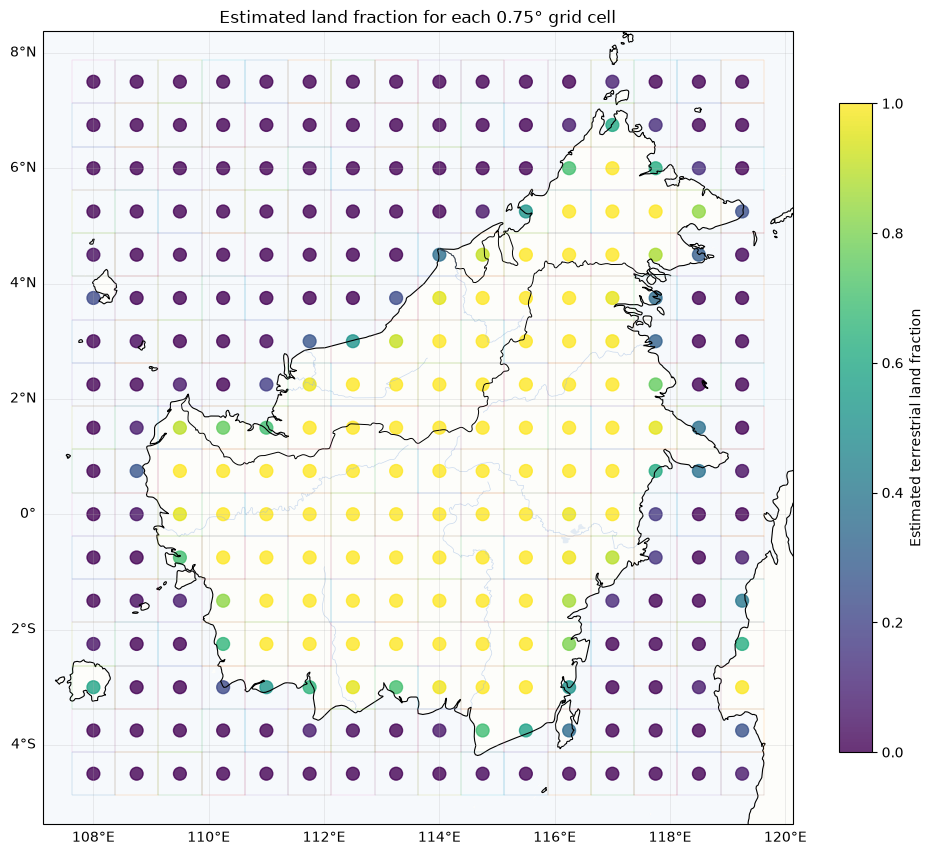

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\figures\02_land_fraction_by_cell.png


In [21]:
# 18. Land-fraction map

fig = plt.figure(figsize=(10, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

add_base_map(ax)

plot_data = cell_summary.copy()

collection = ax.scatter(
    plot_data["grid_lon"],
    plot_data["grid_lat"],
    c=plot_data["land_fraction"],
    s=85,
    alpha=0.8,
    transform=ccrs.PlateCarree(),
)

plot_grid_boundaries(ax, cell_summary)

cb = plt.colorbar(
    collection,
    ax=ax,
    shrink=0.75,
)
cb.set_label("Estimated terrestrial land fraction")

ax.set_title("Estimated land fraction for each 0.75° grid cell")

plt.tight_layout()

fig_path = FIGURES_DIR / "02_land_fraction_by_cell.png"
plt.savefig(
    fig_path,
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Saved:", fig_path)

## 19. Map — Total FIRMS detections by grid cell

Point size represents the total number of FIRMS detections assigned to each cell over the full fire-panel period.

This is the main descriptive map for identifying activity concentration.

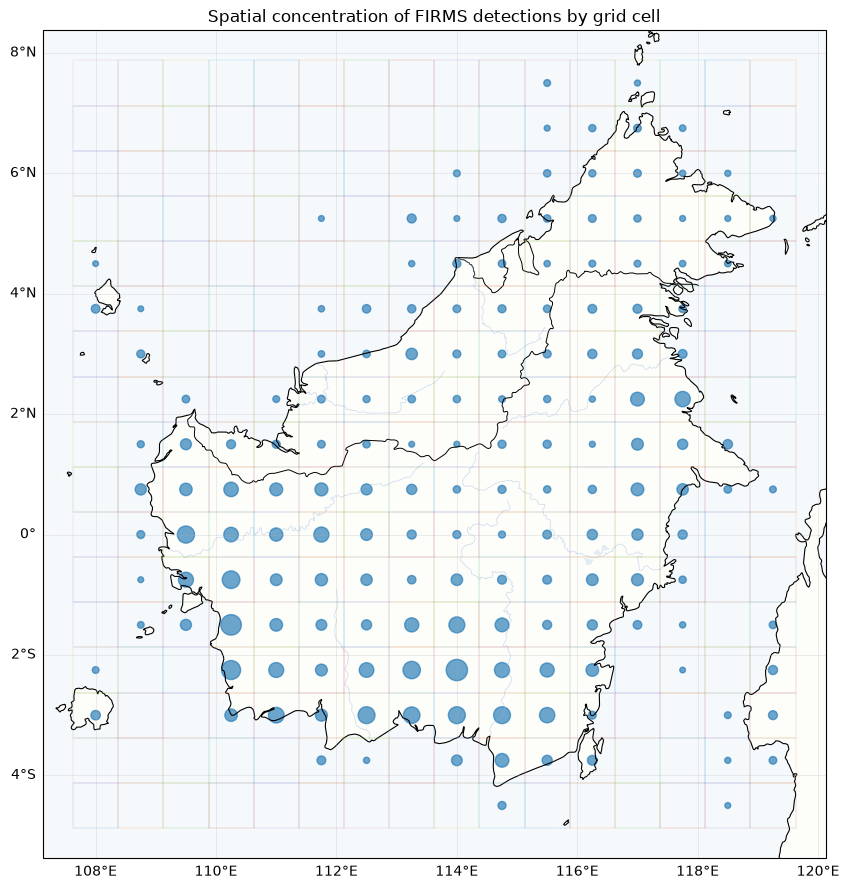

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\figures\03_total_firms_detections_by_cell.png


In [22]:
# 19. Total fire-detection activity map

plot_data = cell_summary[
    cell_summary["total_fire_count"] > 0
].copy()

if len(plot_data):
    max_count = plot_data["total_fire_count"].max()

    marker_size = (
        15
        + 220
        * np.sqrt(
            plot_data["total_fire_count"]
            / max_count
        )
    )

    fig = plt.figure(figsize=(10, 9))
    ax = plt.axes(projection=ccrs.PlateCarree())

    add_base_map(ax)
    plot_grid_boundaries(ax, cell_summary)

    ax.scatter(
        plot_data["grid_lon"],
        plot_data["grid_lat"],
        s=marker_size,
        alpha=0.65,
        transform=ccrs.PlateCarree(),
    )

    ax.set_title(
        "Spatial concentration of FIRMS detections by grid cell"
    )

    plt.tight_layout()

    fig_path = (
        FIGURES_DIR
        / "03_total_firms_detections_by_cell.png"
    )

    plt.savefig(
        fig_path,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

    print("Saved:", fig_path)

## 20. Map — 7-day Emerging detections by grid cell

This plot is especially relevant to the current research motivation.

It shows **where next-day positive detections without recent local detection history occur**.

Marker size represents the number of 7-day Emerging events.

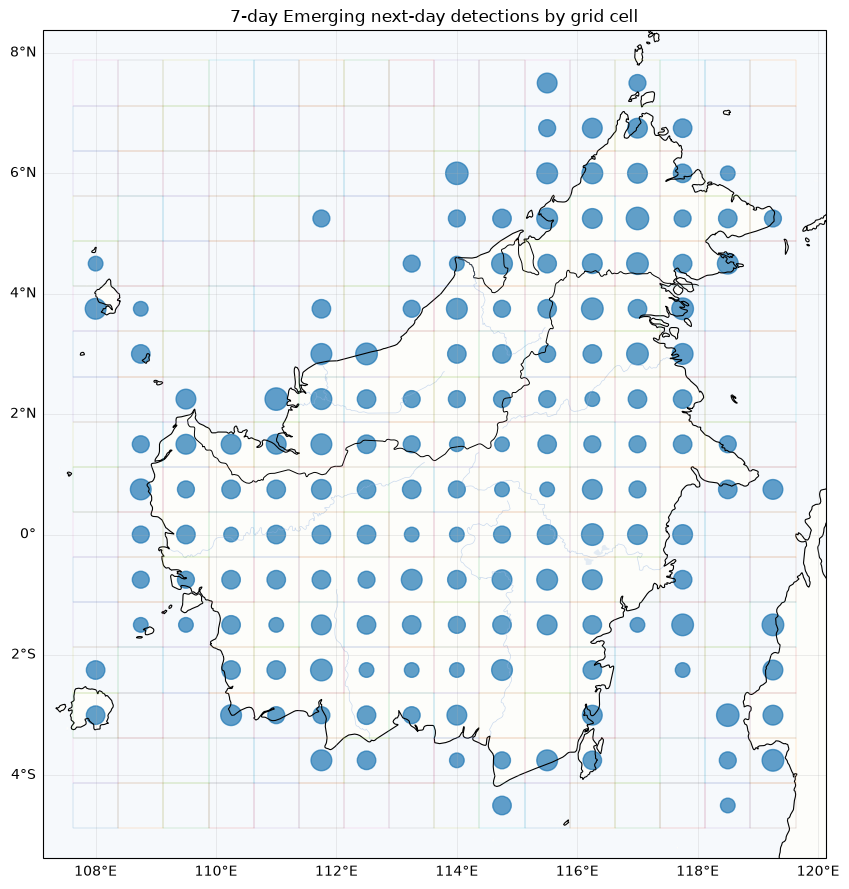

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\figures\04_emerging_7d_by_cell.png


In [23]:
# 20. Emerging hotspot map — all model-ready dates

plot_data = cell_summary[
    cell_summary["emerging_7d_all"] > 0
].copy()

if len(plot_data):
    max_count = plot_data["emerging_7d_all"].max()

    marker_size = (
        20
        + 240
        * np.sqrt(
            plot_data["emerging_7d_all"]
            / max_count
        )
    )

    fig = plt.figure(figsize=(10, 9))
    ax = plt.axes(projection=ccrs.PlateCarree())

    add_base_map(ax)
    plot_grid_boundaries(ax, cell_summary)

    ax.scatter(
        plot_data["grid_lon"],
        plot_data["grid_lat"],
        s=marker_size,
        alpha=0.7,
        transform=ccrs.PlateCarree(),
    )

    ax.set_title(
        "7-day Emerging next-day detections by grid cell"
    )

    plt.tight_layout()

    fig_path = (
        FIGURES_DIR
        / "04_emerging_7d_by_cell.png"
    )

    plt.savefig(
        fig_path,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

    print("Saved:", fig_path)
else:
    print("No 7-day Emerging events found.")

## 21. Map — Validation Emerging detections only

This isolates August 2026, which is the untouched validation period used in the current model-development cycle.

It is useful for seeing whether the 92 seven-day Emerging validation events are highly concentrated in only a few cells.

Validation cells with >=1 Emerging event: 70


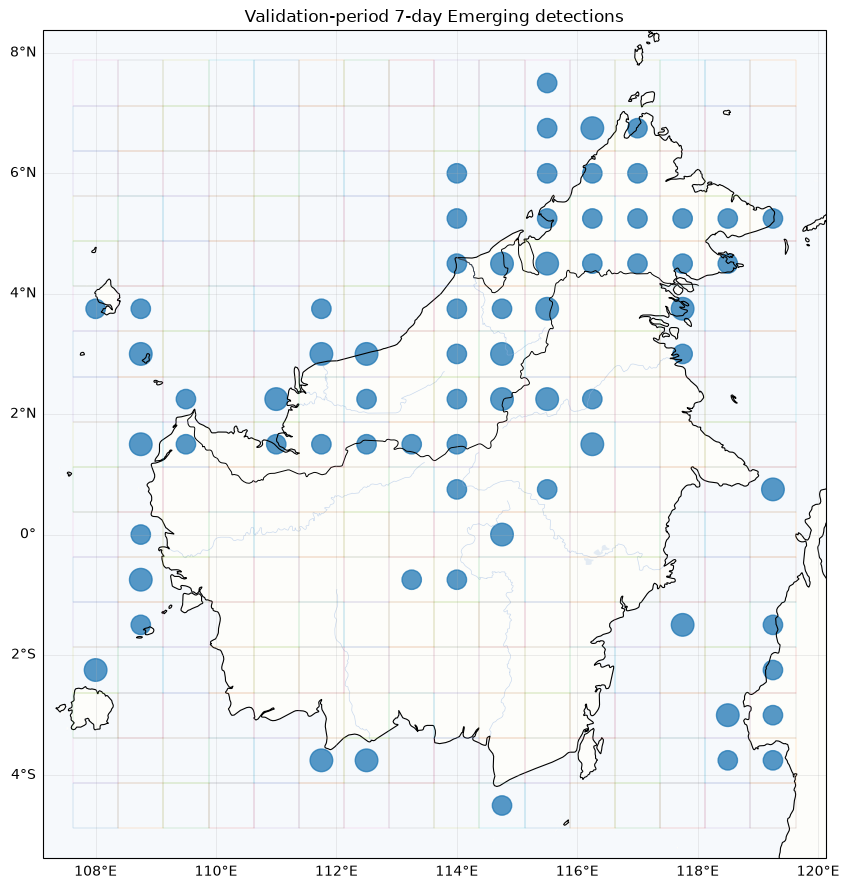

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\figures\05_validation_emerging_7d.png


In [24]:
# 21. Validation-only Emerging map

plot_data = cell_summary[
    cell_summary["validation_emerging_7d"] > 0
].copy()

print(
    "Validation cells with >=1 Emerging event:",
    len(plot_data),
)

if len(plot_data):
    max_count = (
        plot_data["validation_emerging_7d"].max()
    )

    marker_size = (
        25
        + 240
        * np.sqrt(
            plot_data["validation_emerging_7d"]
            / max_count
        )
    )

    fig = plt.figure(figsize=(10, 9))
    ax = plt.axes(projection=ccrs.PlateCarree())

    add_base_map(ax)
    plot_grid_boundaries(ax, cell_summary)

    ax.scatter(
        plot_data["grid_lon"],
        plot_data["grid_lat"],
        s=marker_size,
        alpha=0.75,
        transform=ccrs.PlateCarree(),
    )

    ax.set_title(
        "Validation-period 7-day Emerging detections"
    )

    plt.tight_layout()

    fig_path = (
        FIGURES_DIR
        / "05_validation_emerging_7d.png"
    )

    plt.savefig(
        fig_path,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

    print("Saved:", fig_path)

## 22. Map — Data-driven activity zoom

This map uses the automatically calculated extent of the cells that account for approximately 80% of all FIRMS detections.

The zoom is descriptive only.

**Do not crop the modeling study area yet.**

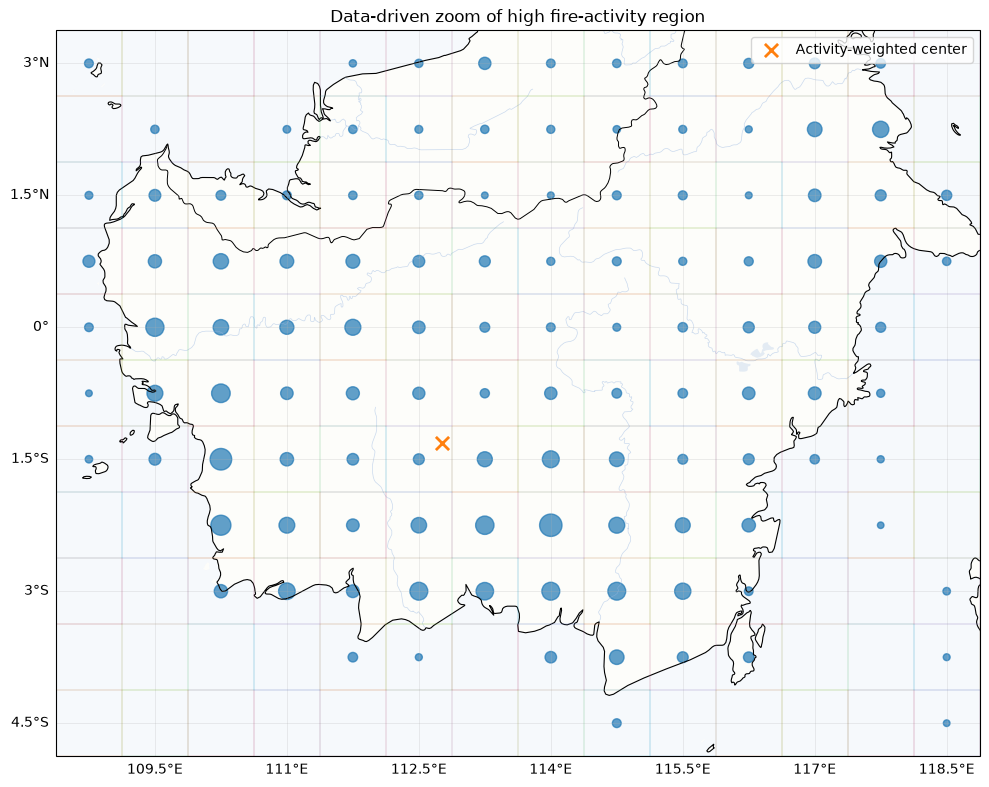

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\figures\06_activity_core_zoom.png


In [25]:
# 22. Fire-activity zoom map

plot_data = cell_summary[
    cell_summary["total_fire_count"] > 0
].copy()

max_count = plot_data["total_fire_count"].max()

marker_size = (
    20
    + 240
    * np.sqrt(
        plot_data["total_fire_count"]
        / max_count
    )
)

fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

add_base_map(
    ax,
    extent=FIRE_ZOOM_EXTENT,
)

plot_grid_boundaries(ax, cell_summary)

ax.scatter(
    plot_data["grid_lon"],
    plot_data["grid_lat"],
    s=marker_size,
    alpha=0.7,
    transform=ccrs.PlateCarree(),
)

ax.scatter(
    [weighted_lon],
    [weighted_lat],
    marker="x",
    s=90,
    linewidth=2,
    transform=ccrs.PlateCarree(),
    label="Activity-weighted center",
)

ax.legend()

ax.set_title(
    "Data-driven zoom of high fire-activity region"
)

plt.tight_layout()

fig_path = (
    FIGURES_DIR
    / "06_activity_core_zoom.png"
)

plt.savefig(
    fig_path,
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Saved:", fig_path)

## 23. Check Emerging detections against land fraction

This is directly related to the supervision concern about water bodies.

We want to know whether any Emerging events are being assigned to strongly water-dominant cells.

If that happens, inspect those cells before graph modeling instead of automatically treating them as physically valid fire locations.

In [26]:
# 23. Emerging events by surface class

emerging_surface_summary = (
    cell_summary
    .groupby(
        "surface_class",
        observed=False,
    )
    .agg(
        cells=("cell_id", "size"),
        emerging_7d_all=("emerging_7d_all", "sum"),
        emerging_3d_all=("emerging_3d_all", "sum"),
        validation_emerging_7d=(
            "validation_emerging_7d",
            "sum",
        ),
        total_fire_count=("total_fire_count", "sum"),
    )
)

display(emerging_surface_summary)

suspicious_emerging_cells = (
    cell_summary[
        (cell_summary["land_fraction"] < 0.20)
        &
        (cell_summary["emerging_7d_all"] > 0)
    ]
    [
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "province",
            "land_fraction",
            "emerging_7d_all",
            "validation_emerging_7d",
            "total_fire_count",
        ]
    ]
    .sort_values(
        "emerging_7d_all",
        ascending=False,
    )
)

print(
    "Water-dominant cells with >=1 Emerging event:",
    len(suspicious_emerging_cells),
)

display(suspicious_emerging_cells)

,cells,emerging_7d_all,emerging_3d_all,validation_emerging_7d,total_fire_count
surface_class,,,,,
Water-dominant,145,108,188,34,2868.0
Mixed land/water,34,124,235,18,30284.0
Land-dominant,93,271,551,40,113162.0


Water-dominant cells with >=1 Emerging event: 37


,cell_id,grid_lat,grid_lon,province,land_fraction,emerging_7d_all,validation_emerging_7d,total_fire_count
46,Kalimantan_-3.00_118.50,-3.00,118.50,NaN,0.074173,7,2,21.0
148,Kalimantan_2.25_111.00,2.25,111.00,NaN,0.181946,7,2,23.0
232,Kalimantan_6.00_114.00,6.00,114.00,NaN,0.000000,7,1,25.0
77,Kalimantan_-1.50_117.75,-1.50,117.75,NaN,0.000000,6,2,8.0
21,Kalimantan_-3.75_111.75,-3.75,111.75,NaN,0.067005,5,2,170.0
234,Kalimantan_6.00_115.50,6.00,115.50,NaN,0.000167,5,1,46.0
251,Kalimantan_6.75_116.25,6.75,116.25,NaN,0.068153,4,2,39.0
146,Kalimantan_2.25_109.50,2.25,109.50,NaN,0.063955,4,1,59.0
109,Kalimantan_0.00_117.75,0.00,117.75,NaN,0.156582,4,0,231.0
266,Kalimantan_7.50_115.50,7.50,115.50,NaN,0.000000,4,1,22.0


## 24. Candidate node mask for later GAT

This notebook does **not** modify the model-ready dataset.

Instead, it saves a candidate mask with:

- `keep_candidate = True` for all cells that are sufficiently terrestrial **or** have any observed fire detections;
- `keep_candidate = False` only for strongly water-dominant cells with zero detections.

This mask should be reviewed visually before it is used in Notebook 14.

In [27]:
# 24. Candidate graph-node mask

cell_summary["keep_candidate"] = (
    ~cell_summary["candidate_exclude_from_graph"]
)

node_mask = cell_summary[
    [
        "cell_id",
        "grid_lat",
        "grid_lon",
        "province",
        "land_fraction",
        "surface_class",
        "total_fire_count",
        "active_cell_days",
        "emerging_7d_all",
        "emerging_3d_all",
        "validation_emerging_7d",
        "keep_candidate",
    ]
].copy()

print("All grid cells       :", len(node_mask))
print(
    "Candidate keep cells:",
    int(node_mask["keep_candidate"].sum()),
)
print(
    "Candidate exclusions:",
    int((~node_mask["keep_candidate"]).sum()),
)

display(
    node_mask
    .sort_values(
        [
            "keep_candidate",
            "land_fraction",
        ]
    )
    .head(30)
)

All grid cells       : 272
Candidate keep cells: 166
Candidate exclusions: 106


,cell_id,grid_lat,grid_lon,province,land_fraction,surface_class,total_fire_count,active_cell_days,emerging_7d_all,emerging_3d_all,validation_emerging_7d,keep_candidate
0,Kalimantan_-4.50_108.00,-4.50,108.00,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False
1,Kalimantan_-4.50_108.75,-4.50,108.75,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False
2,Kalimantan_-4.50_109.50,-4.50,109.50,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False
3,Kalimantan_-4.50_110.25,-4.50,110.25,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False
4,Kalimantan_-4.50_111.00,-4.50,111.00,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False
5,Kalimantan_-4.50_111.75,-4.50,111.75,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False
6,Kalimantan_-4.50_112.50,-4.50,112.50,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False
7,Kalimantan_-4.50_113.25,-4.50,113.25,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False
8,Kalimantan_-4.50_114.00,-4.50,114.00,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False
11,Kalimantan_-4.50_116.25,-4.50,116.25,NaN,0.0,Water-dominant,0.0,0.0,0,0,0,False


## 25. Concentration of Emerging events

Before building a graph model, it is useful to know whether Emerging events occur broadly across the spatial network or are concentrated in a small subset of nodes.

We report how many cells account for 50% and 80% of 7-day Emerging events.

In [28]:
# 25. Emerging-event concentration

em_ranked = (
    cell_summary[
        cell_summary["emerging_7d_all"] > 0
    ]
    .sort_values(
        "emerging_7d_all",
        ascending=False,
    )
    .copy()
)

total_emerging = em_ranked["emerging_7d_all"].sum()

if total_emerging > 0:
    em_ranked["share"] = (
        em_ranked["emerging_7d_all"]
        / total_emerging
    )

    em_ranked["cumulative_share"] = (
        em_ranked["share"].cumsum()
    )

    cells_50 = int(
        np.argmax(
            em_ranked["cumulative_share"].to_numpy()
            >= 0.50
        )
        + 1
    )

    cells_80 = int(
        np.argmax(
            em_ranked["cumulative_share"].to_numpy()
            >= 0.80
        )
        + 1
    )

    print("Total 7-day Emerging events:", int(total_emerging))
    print(
        "Cells with >=1 Emerging event:",
        len(em_ranked),
    )
    print(
        "Cells covering ~50% Emerging:",
        cells_50,
    )
    print(
        "Cells covering ~80% Emerging:",
        cells_80,
    )

    display(
        em_ranked[
            [
                "cell_id",
                "grid_lat",
                "grid_lon",
                "province",
                "emerging_7d_all",
                "cumulative_share",
            ]
        ].head(25)
    )

Total 7-day Emerging events: 503
Cells with >=1 Emerging event: 158
Cells covering ~50% Emerging: 51
Cells covering ~80% Emerging: 99


,cell_id,grid_lat,grid_lon,province,emerging_7d_all,cumulative_share
46,Kalimantan_-3.00_118.50,-3.00,118.50,NaN,7,0.013917
232,Kalimantan_6.00_114.00,6.00,114.00,NaN,7,0.027833
220,Kalimantan_5.25_117.00,5.25,117.00,NaN,7,0.041750
148,Kalimantan_2.25_111.00,2.25,111.00,NaN,7,0.055666
53,Kalimantan_-2.25_111.75,-2.25,111.75,Kalimantan Tengah,6,0.067594
31,Kalimantan_-3.75_119.25,-3.75,119.25,NaN,6,0.079523
204,Kalimantan_4.50_117.00,4.50,117.00,NaN,6,0.091451
107,Kalimantan_0.00_116.25,0.00,116.25,Kalimantan Timur,6,0.103380
79,Kalimantan_-1.50_119.25,-1.50,119.25,NaN,6,0.115308
187,Kalimantan_3.75_116.25,3.75,116.25,Kalimantan Timur,6,0.127237


## 26. Save all outputs

These outputs will be used by the wind-direction analysis and later GAT notebooks.

In [29]:
# 26. Save outputs

cell_summary_csv = (
    RESULTS_DIR
    / "kalimantan_cell_spatial_summary.csv"
)

node_mask_csv = (
    RESULTS_DIR
    / "kalimantan_candidate_graph_node_mask.csv"
)

top_fire_csv = (
    RESULTS_DIR
    / "top_fire_cells.csv"
)

top_emerging_csv = (
    RESULTS_DIR
    / "top_emerging_cells.csv"
)

province_summary_csv = (
    RESULTS_DIR
    / "approximate_province_summary.csv"
)

activity_core_csv = (
    RESULTS_DIR
    / "activity_core_80pct_cells.csv"
)

cell_summary.drop(
    columns="geometry"
).to_csv(
    cell_summary_csv,
    index=False,
)

node_mask.to_csv(
    node_mask_csv,
    index=False,
)

top_fire_cells.to_csv(
    top_fire_csv,
    index=False,
)

top_emerging_cells.to_csv(
    top_emerging_csv,
    index=False,
)

province_summary.to_csv(
    province_summary_csv,
    index=False,
)

activity_core.drop(
    columns="geometry"
).to_csv(
    activity_core_csv,
    index=False,
)

print("Saved:")
for path in [
    cell_summary_csv,
    node_mask_csv,
    top_fire_csv,
    top_emerging_csv,
    province_summary_csv,
    activity_core_csv,
]:
    print("-", path)

Saved:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\kalimantan_cell_spatial_summary.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\kalimantan_candidate_graph_node_mask.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\top_fire_cells.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\top_emerging_cells.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\approximate_province_summary.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_zoom_landwater\activity_core_80pct_cells.csv


## 27. Automatic diagnostic summary

This cell summarizes what should be discussed before changing the study area or deleting any graph nodes.

In [30]:
# 27. Diagnostic summary

n_water = int(
    (cell_summary["surface_class"] == "Water-dominant").sum()
)

n_mixed = int(
    (cell_summary["surface_class"] == "Mixed land/water").sum()
)

n_land = int(
    (cell_summary["surface_class"] == "Land-dominant").sum()
)

n_exclude = int(
    cell_summary["candidate_exclude_from_graph"].sum()
)

water_fire_cells = int(
    (
        (cell_summary["surface_class"] == "Water-dominant")
        &
        (cell_summary["total_fire_count"] > 0)
    ).sum()
)

water_emerging_cells = int(
    (
        (cell_summary["surface_class"] == "Water-dominant")
        &
        (cell_summary["emerging_7d_all"] > 0)
    ).sum()
)

print("=== Notebook 12 spatial diagnostic ===")
print("Total cells            :", len(cell_summary))
print("Land-dominant cells    :", n_land)
print("Mixed land/water cells :", n_mixed)
print("Water-dominant cells   :", n_water)
print()
print(
    "Water-dominant cells with any FIRMS detections:",
    water_fire_cells,
)
print(
    "Water-dominant cells with Emerging detections:",
    water_emerging_cells,
)
print(
    "Conservative candidate graph exclusions:",
    n_exclude,
)
print()
print(
    "Activity-weighted coordinate:",
    f"{weighted_lat:.3f}, {weighted_lon:.3f}",
)
print(
    "80% activity-core cell count:",
    len(activity_core),
)
print(
    "80% activity-core share:",
    round(core_share, 4),
)
print(
    "Visual zoom extent:",
    FIRE_ZOOM_EXTENT,
)

=== Notebook 12 spatial diagnostic ===
Total cells            : 272
Land-dominant cells    : 93
Mixed land/water cells : 34
Water-dominant cells   : 145

Water-dominant cells with any FIRMS detections: 39
Water-dominant cells with Emerging detections: 37
Conservative candidate graph exclusions: 106

Activity-weighted coordinate: -1.311, 112.768
80% activity-core cell count: 31
80% activity-core share: 0.8028
Visual zoom extent: [np.float64(108.375), np.float64(118.875), np.float64(-4.875), np.float64(3.375)]




### 1. "Kalimantannya spesifik di mana?"

Use:

- `approximate_province_summary`
- `top_fire_cells`
- `top_emerging_cells`
- the activity zoom figure

Do not name a province unless the output actually supports it.

---

### 2. "Kalau di sampingnya sungai atau danau kan tidak mungkin muncul titik api."

Answer:

> Benar bahwa titik api tidak muncul di permukaan air, tetapi unit analisis saya masih berupa grid 0.75°. Satu grid bisa berisi daratan, sungai, danau, atau pesisir sekaligus. Karena itu saya tidak langsung membuang grid yang mengandung air. Saya menghitung proporsi daratan per grid, lalu hanya menandai grid yang sangat dominan air dan tidak pernah memiliki deteksi FIRMS sebagai kandidat untuk dikeluarkan dari graph.

---

### 3. What should happen next?

If the spatial maps and node mask look reasonable:

**Notebook 13 — Wind Direction & Neighbor Alignment Analysis**

The key next question will be:

> Given an active cell today, are neighboring cells lying in the wind direction more likely to become Emerging positives tomorrow?

Only after that result should wind be promoted from a normal weather feature into a graph-edge feature.